# ANN (MLP) | X-IIoTID | target: `class2` (10-class, macro-averaged)
Tayyab (SP24-BCS-004). Settings and decisions are tracked in `AUDIT_LOG.md`; hyperparameter sources are in `HYPERPARAMETER_SOURCES.md` (both in the project root).

Plan: 20% test set (stratified), stratified 5-fold validation on the other 80%, hyperparameters fixed from papers (no tuning), test set used once.

## 1. Imports and setup
**Q1.** Import the libraries and set a global `RANDOM_STATE`.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, matthews_corrcoef, confusion_matrix, classification_report)

# max_iter = number of epochs from the paper; sklearn warns that the loss is still falling after the last epoch
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42

**Q2.** Define the ANN hyperparameters (fixed from the papers) and the duplicate-removal switch.

In [2]:
# Dataset-specific hyperparameters (see HYPERPARAMETER_SOURCES.md, ANN section)
# Source: Al-Hawawreh, Sitnikova & Aboutorab (2022), "X-IIoTID: A Connectivity-Agnostic and Device-Agnostic
# Intrusion Data Set for Industrial Internet of Things", IEEE Internet of Things Journal 9(5):3962-3977,
# doi:10.1109/JIOT.2021.3102056 (X-IIoTID dataset paper, DNN baseline)
# Paper: 3 hidden layers x 200 neurons, ReLU, sigmoid (binary) / softmax (multi-class) output,
#        batch size 250, 10 epochs, optimizer RMSprop
# MLPClassifier mapping: the output layer is chosen automatically (logistic for binary, softmax for multi-class);
# RMSprop is not available in scikit-learn, so Adam is used (Adam = RMSprop + momentum), learning rate 0.001
# (Keras/sklearn default; the paper gives none); no L2 penalty (alpha=0), as none is stated in the paper
HP = dict(hidden_layer_sizes=(200, 200, 200), activation="relu", solver="adam", learning_rate_init=0.001,
          batch_size=250, max_iter=10, alpha=0.0, shuffle=True, early_stopping=False, random_state=RANDOM_STATE)

DEDUPLICATE = False

## 2. Load the dataset
**Q3.** Load `X-IIoTID dataset.csv`. How many rows and columns are there?

In [3]:
# low_memory=False: most columns mix numbers with "-", so pandas reads the whole file before choosing types
df = pd.read_csv("../../../X-IIoTID dataset.csv", low_memory=False)

In [4]:
df.shape

(820834, 68)

## 3. Explore the data
**Q4.** Show `head()`, `info()`, `describe()` and the class distribution of `class2`. Is it balanced? Which class is the rarest?

In [5]:
df.head()

,Date,Timestamp,Scr_IP,Scr_port,Des_IP,Des_port,Protocol,Service,Duration,Scr_bytes,...,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,class1,class2,class3
0,9/01/2020,1578540956,192.168.2.199,49278,192.168.2.10,80,tcp,http,0.67369,13437,...,5,0,0,0,0,0,0,Scanning_vulnerability,Reconnaissance,Attack
1,13/01/2020,1578871873,10.0.1.5,39769,131.236.3.92,53,udp,dns,0.000083,78,...,0,0,0,0,0,0,0,Normal,Normal,Normal
2,9/01/2020,1578522486,172.24.1.80,59050,172.24.1.1,53,udp,dns,0.000132,38,...,0,0,0,0,0,0,0,Normal,Normal,Normal
3,27/02/2020,1582757640,192.168.2.196,37966,192.168.2.10,1880,tcp,websocket,9.378481,1121,...,0,1,1,1,1,1,1,Normal,Normal,Normal
4,16/12/2019,1576452612,172.24.1.80,38233,172.24.1.1,53,udp,dns,0.000074,-,...,0,0,0,0,0,0,0,Normal,Normal,Normal


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 820834 entries, 0 to 820833
Data columns (total 68 columns):
 #   Column                       Non-Null Count   Dtype
---  ------                       --------------   -----
 0   Date                         820503 non-null  str  
 1   Timestamp                    820537 non-null  str  
 2   Scr_IP                       820834 non-null  str  
 3   Scr_port                     820834 non-null  str  
 4   Des_IP                       820834 non-null  str  
 5   Des_port                     820834 non-null  str  
 6   Protocol                     820834 non-null  str  
 7   Service                      820834 non-null  str  
 8   Duration                     820834 non-null  str  
 9   Scr_bytes                    820834 non-null  str  
 10  Des_bytes                    820834 non-null  str  
 11  Conn_state                   820834 non-null  int64
 12  missed_bytes                 820834 non-null  str  
 13  is_syn_only                  820834 non-

In [7]:
df.describe()

,Conn_state,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged
count,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000
mean,0.851623,0.051186,0.267717,0.087305,0.082730,0.072650,0.082620,0.355309,0.082456
std,0.355474,0.220377,1.178027,0.282282,0.275475,0.259562,0.275307,0.478607,0.275059
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<Axes: title={'center': 'Class distribution: class2'}, xlabel='class2'>

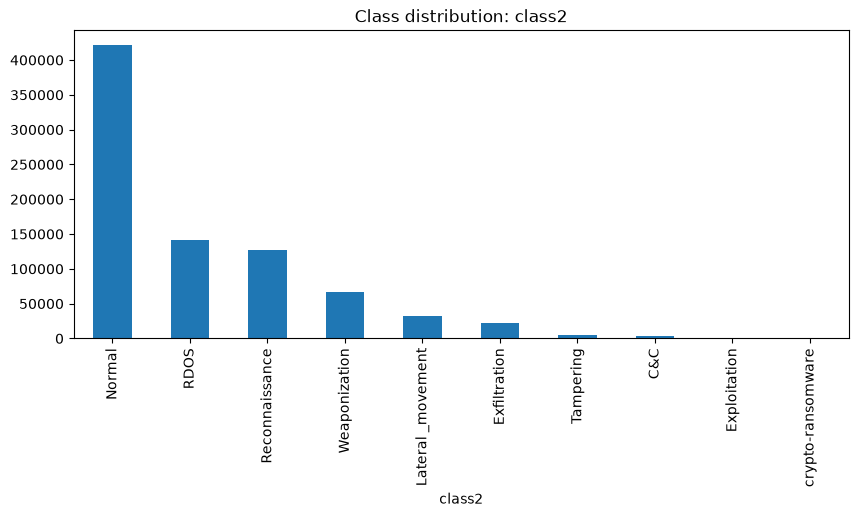

In [8]:
df["class2"].value_counts().plot(kind="bar", figsize=(10, 4), title="Class distribution: class2")

In [9]:
df["class2"].value_counts(normalize=True).round(4)

class2
Normal               0.5134
RDOS                 0.1721
Reconnaissance       0.1554
Weaponization        0.0819
Lateral _movement    0.0385
Exfiltration         0.0270
Tampering            0.0062
C&C                  0.0035
Exploitation         0.0014
crypto-ransomware    0.0006
Name: proportion, dtype: float64

**Q5.** How are missing values marked in this dataset, and how many are there?

In [10]:
# Empty fields are written as "-" (and "?" in Protocol), so turn them into real NaN
df = df.replace(["-", "?"], np.nan)

In [11]:
# Feature columns that should be numbers but were read as text because of the "-"
text_cols = ["Date", "Timestamp", "Scr_IP", "Scr_port", "Des_IP", "Des_port", "Protocol", "Service", "anomaly_alert",
             "class1", "class2", "class3"]
num_cols = [col for col in df.columns if col not in text_cols]

# errors="coerce": a few broken cells ("#DIV/0!", "excel", "aza") also become NaN
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage[missing_percentage > 0].sort_values(ascending=False).round(2)

Des_bytes_ratio     27.27
Scr_bytes_ratio     27.27
byte_rate           27.27
total_bytes         27.27
Des_bytes           27.27
Scr_bytes           27.27
paket_rate          27.27
Scr_ip_bytes        18.61
Scr_packts_ratio    18.61
Des_pkts_ratio      18.61
total_packet        18.61
Scr_pkts            18.61
Des_pkts            18.61
Des_ip_bytes        18.61
Duration             9.23
Std_kbmemused        0.14
Avg_kbmemused        0.14
Std_ldavg_1          0.06
Avg_ldavg_1          0.06
Avg_user_time        0.06
Std_wtps             0.06
Std_rtps             0.06
Avg_tps              0.06
Std_tps              0.06
Avg_rtps             0.06
Avg_wtps             0.06
Avg_system_time      0.06
Avg_iowait_time      0.06
Std_iowait_time      0.06
Std_system_time      0.06
Avg_nice_time        0.06
Std_nice_time        0.06
Std_ideal_time       0.06
Std_user_time        0.06
Avg_ideal_time       0.06
Avg_num_Proc/s       0.06
Avg_num_cswch/s      0.06
Std_num_proc/s       0.06
std_num_cswc

## 4. Clean the data
**Q6.** Which columns have the same value in every row? Drop them.

In [13]:
# A column with only one value cannot help the model separate anything
constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) == 1]
constant_cols

['Bad_checksum', 'is_SYN_with_RST']

In [14]:
df = df.drop(columns=constant_cols)
df.shape

(820834, 66)

**Q7.** Drop the identifier columns. Why do they cause overfitting?

In [15]:
# Date/time, IP addresses and ports identify one capture, not the attack itself
id_cols = ["Date", "Timestamp", "Scr_IP", "Scr_port", "Des_IP", "Des_port"]
df = df.drop(columns=id_cols)
df.shape

(820834, 60)

**Q8.** How many duplicate rows are there now?

In [16]:
no_of_duplicates = df.duplicated().sum()
no_of_duplicates

np.int64(119685)

In [17]:
if DEDUPLICATE:
    df = df.drop_duplicates().reset_index(drop=True)
df.shape

(820834, 60)

## 5. Targets and split
**Q9.** Build the features `X` and the target `y` (`class2`), then split 80/20 with stratification. Do the class shares match between train and test?

In [18]:
# All three targets leave the features, otherwise the model would just read the answer
X = df.drop(columns=["class1", "class2", "class3"])
# The model needs numbers, so the class names become 0, 1, 2, ... (alphabetical)
le = LabelEncoder()
y = pd.Series(le.fit_transform(df["class2"]), index=df.index)
class_names = list(le.classes_)

# Stratify on class1 (the finest labels) in all three notebooks, so every model uses the exact same rows
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df["class1"])
X_train.shape, X_test.shape

((656667, 57), (164167, 57))

In [19]:
# Class shares should be (almost) the same in train and test
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4)

,train,test
4,0.5134,0.5134
5,0.1721,0.1721
6,0.1554,0.1554
8,0.0819,0.0819
3,0.0385,0.0385
1,0.0270,0.0270
7,0.0062,0.0062
0,0.0035,0.0035
2,0.0014,0.0014
9,0.0006,0.0006


## 6. Encode and scale the features
**Q10.** Encode the features. Why are the encoders fitted after the split?

In [20]:
onehot_cols = ["Protocol", "Service", "anomaly_alert"]

X_train = X_train.copy()
X_test = X_test.copy()

# Missing text values become their own category
for col in onehot_cols:
    X_train[col] = X_train[col].fillna("missing")
    X_test[col] = X_test[col].fillna("missing")

# Missing numbers become -1: no real value here is negative, so "missing" stays apart from real values
X_train = X_train.fillna(-1)
X_test = X_test.fillna(-1)

# Columns come from the training set; the test set is lined up to them (unseen categories dropped, missing ones = 0)
X_train = pd.get_dummies(X_train, columns=onehot_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=onehot_cols, dtype=int).reindex(columns=X_train.columns, fill_value=0)

X_train.shape, X_test.shape

((656667, 78), (164167, 78))

**Q11.** Scale the features with `StandardScaler`. Why does a neural network need scaling, and why is the scaler fitted on the training set only?

In [21]:
# Neural networks need features on the same scale (trees did not); the scaler learns mean/std from the training set only
# NaN was filled with -1 (same as for the trees); after scaling, -1 simply becomes a low value the network can learn as 'missing'
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
X_train_s.shape, X_test_s.shape

((656667, 78), (164167, 78))

## 7. Validation with stratified 5-fold
**Q12.** Run stratified 5-fold validation with the fixed hyperparameters. Is the validation score stable across the folds?

In [22]:
# 5 rounds on the 80%: each round trains on 4 parts (64% of all data) and validates on 1 part (16%)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_scores = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    # A fresh scaler per fold, fitted on the fold's training part only (the validation part stays unseen)
    sc = StandardScaler()
    X_tr = sc.fit_transform(X_train.iloc[train_idx])
    X_va = sc.transform(X_train.iloc[val_idx])
    m = MLPClassifier(**HP)
    m.fit(X_tr, y_train.iloc[train_idx])
    pred = m.predict(X_va)
    fold_scores.append({"fold": fold,
                        "val_accuracy": accuracy_score(y_train.iloc[val_idx], pred),
                        "val_f1_macro": f1_score(y_train.iloc[val_idx], pred, average="macro")})

fold_df = pd.DataFrame(fold_scores).set_index("fold")
fold_df.round(4)

,val_accuracy,val_f1_macro
fold,,
1,0.9886,0.9609
2,0.9885,0.9577
3,0.9887,0.9565
4,0.9884,0.9611
5,0.9884,0.9633


In [23]:
# Mean and spread over the 5 folds (small std = stable model)
fold_df.agg(["mean", "std"]).round(4)

,val_accuracy,val_f1_macro
mean,0.9885,0.9599
std,0.0001,0.0028


## 8. Final model
**Q13.** Train the final model on the full training set. How long does it take? How many epochs did it run, and how many weights does the network have?

In [24]:
model = MLPClassifier(**HP)

start = time.perf_counter()
model.fit(X_train_s, y_train)
train_time = time.perf_counter() - start

# Epochs actually run, and the number of learned weights + biases in the network
n_weights = sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_)
train_time, model.n_iter_, n_weights

(131.04993400000012, 10, 98210)

## 9. Evaluation on the test set (used once)
**Q14.** Predict on the test set and measure the inference latency (ms per sample).

In [25]:
# Latency = predict() time on the whole test set / number of test rows, in ms per sample
start = time.perf_counter()
y_pred = model.predict(X_test_s)
latency_ms = (time.perf_counter() - start) / len(X_test_s) * 1000

# Probabilities are needed for ROC-AUC and Log-Loss
y_proba = model.predict_proba(X_test_s)
latency_ms

0.0032038643576336647

**Q15.** Compute Accuracy, Precision, Recall, F1, ROC-AUC, Log-Loss, FPR, MCC and TP/TN/FP/FN (macro-averaged). Which classes are the hardest?

In [26]:
labels = np.arange(len(class_names))

# Macro = compute per class, then take the plain average, so small classes count as much as big ones
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=labels)
logloss = log_loss(y_test, y_proba, labels=labels)
mcc = matthews_corrcoef(y_test, y_pred)

# One-vs-rest counts per class from the confusion matrix (rows = actual, columns = predicted)
cm = confusion_matrix(y_test, y_pred, labels=labels)
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
TN = cm.sum() - (TP + FP + FN)
fpr = np.mean(FP / (FP + TN))

pd.Series({"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1,
           "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc}).round(4)

Accuracy     0.9887
Precision    0.9763
Recall       0.9491
F1           0.9618
ROC-AUC      0.9996
Log-Loss     0.0316
FPR          0.0019
MCC          0.9833
dtype: float64

In [27]:
# Per-class view: which classes does the network miss?
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

                   precision    recall  f1-score   support

              C&C       0.88      0.79      0.83       573
     Exfiltration       1.00      1.00      1.00      4427
     Exploitation       0.99      0.83      0.90       226
Lateral _movement       0.99      0.98      0.98      6320
           Normal       0.99      0.99      0.99     84283
             RDOS       1.00      1.00      1.00     28252
   Reconnaissance       0.98      0.97      0.97     25518
        Tampering       0.96      0.96      0.96      1025
    Weaponization       1.00      1.00      1.00     13451
crypto-ransomware       0.98      0.97      0.97        92

         accuracy                           0.99    164167
        macro avg       0.98      0.95      0.96    164167
     weighted avg       0.99      0.99      0.99    164167



In [28]:
# Macro-averaged one-vs-rest counts (these go in Results.xlsx)
TP.mean(), TN.mean(), FP.mean(), FN.mean()

(np.float64(16231.9),
 np.float64(147565.5),
 np.float64(184.8),
 np.float64(184.8))

**Q16.** Compare the train and test accuracy. Is the network overfitting or underfitting?

In [29]:
# Train much higher than test = overfitting; both low and close = underfitting
train_acc = accuracy_score(y_train, model.predict(X_train_s))
test_acc = accuracy_score(y_test, y_pred)
round(train_acc, 4), round(test_acc, 4)

(0.99, 0.9887)

## 10. Visualizations
**Q17.** Plot the confusion matrix.

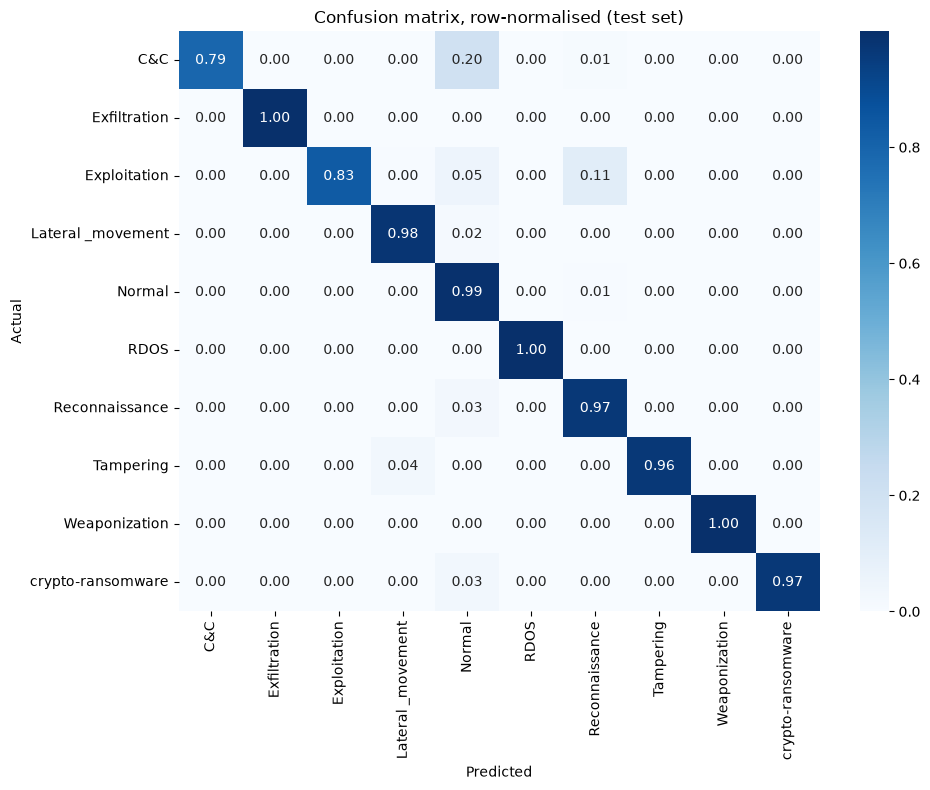

In [30]:
# normalize="true": each row sums to 1, so the diagonal is the recall of each class
cm_norm = confusion_matrix(y_test, y_pred, labels=labels, normalize="true")

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix, row-normalised (test set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

**Q18.** Plot the training loss per epoch. Is the loss still falling at the last epoch?

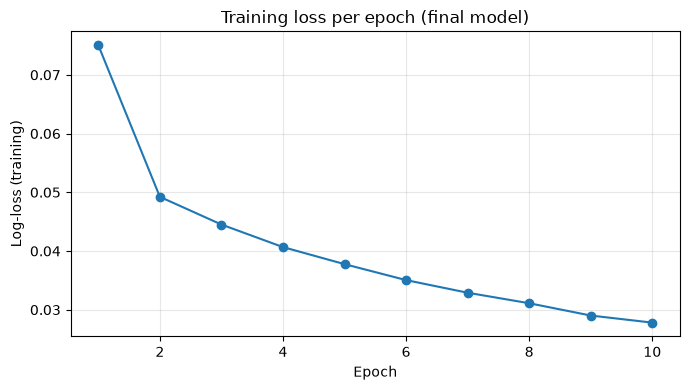

In [31]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(model.loss_curve_) + 1), model.loss_curve_, marker="o")
plt.title("Training loss per epoch (final model)")
plt.xlabel("Epoch"); plt.ylabel("Log-loss (training)")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 11. Results table
**Q19.** Collect all the numbers in one results table.

In [32]:
results = pd.DataFrame([{
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1,
    "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc,
    "Inference Latency (ms/sample)": latency_ms, "Training time (s)": train_time,
    "Test time (s)": latency_ms * len(y_test) / 1000,
    "TP": TP.mean(), "TN": TN.mean(), "FP": FP.mean(), "FN": FN.mean(),
    "Test rows": len(y_test),
}], index=["ANN - class2 (macro)"])
results.T

,ANN - class2 (macro)
Accuracy,0.988743
Precision,0.976341
Recall,0.949069
F1-Score,0.961758
ROC-AUC,0.999606
Log-Loss,0.031598
FPR,0.001862
MCC,0.983274
Inference Latency (ms/sample),0.003204
Training time (s),131.049934


## 12. Discussion (for the report)
**Q20.** How does the ANN compare with the Decision Tree on this target (accuracy, F1, MCC, inference latency, training time)?

**Q21.** Which attack types are confused with each other, and why?

**Q22.** How does the class imbalance affect the results?

**Q23.** What are the limitations of this model?